In [1]:
# ============================================================
# SMART-PDM — LAYER 1
# RAW SIGNAL AUDIT — V3 (Streaming / Chunked, Memory-Safe)
# ============================================================
#
# این نسخه برای دیتاست‌های بزرگ طراحی شده است:
#   - فایل‌های fast.csv و slow.csv تکه‌تکه خوانده می‌شوند.
#   - هیچ آرایه یا DataFrame بزرگی در حافظه ساخته نمی‌شود.
#   - محاسبات آماری به‌صورت online انجام می‌شوند.
#   - duplicate timestamps با set کوچک از hash عددی محاسبه می‌شود.
# ============================================================


# ============================================================
# CELL 1 — IMPORTS & CONFIGURATION
# ============================================================

from pathlib import Path
import json
import warnings
import math
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

RAW_DATASET_DIR = Path(r"D:\PROJECT\SMART-PDM-Dataset")
LAYER1_DIR      = Path(r"D:\PROJECT\SMART-PDM-Dataset-Layer1")

MANIFEST_PATH = LAYER1_DIR / "layer1_fixed_split_manifest.csv"
CONFIG_PATH   = LAYER1_DIR / "layer1_split_config.json"

AUDIT_DIR  = LAYER1_DIR / "audit_v3"
REPORT_DIR = AUDIT_DIR / "reports"
PLOT_DIR   = AUDIT_DIR / "plots"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DATASET STRUCTURE
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Bearing", "Heating", "Motor"]
SPLITS      = ["train", "validation", "test"]

# ------------------------------------------------------------
# EXPLICIT SIGNAL DEFINITIONS
# ------------------------------------------------------------

FAST_TIME_COLUMN    = "UnixTimestamp (us)"
FAST_SIGNAL_COLUMNS = ["Current", "Vibration"]

SLOW_TIME_COLUMN    = "Ts"
SLOW_SIGNAL_COLUMNS = ["A", "ActE", "ActP", "AppP", "Fr", "PF", "RctP", "V"]

# ------------------------------------------------------------
# EXPECTED SAMPLING
# ------------------------------------------------------------

EXPECTED_FAST_FS = 2049.0
EXPECTED_SLOW_FS = 1.0

FAST_TIME_UNIT = "microseconds"
SLOW_TIME_UNIT = "seconds"

# ------------------------------------------------------------
# AUDIT PARAMETERS
# ------------------------------------------------------------

IQR_MULTIPLIER        = 3.0
NEAR_CONSTANT_STD_EPS = 1e-12
FAST_FS_TOLERANCE     = 0.15
SLOW_FS_TOLERANCE     = 0.20
RANDOM_SEED           = 42

# ------------------------------------------------------------
# CHUNKED / STREAMING PARAMETERS
# ------------------------------------------------------------

CHUNK_SIZE         = 200_000   # تعداد ردیف در هر chunk
MAX_SAMPLE_ROWS    = 5_000     # حداکثر ردیف برای پلات/sample
MAX_TS_HASH_SET    = 2_000_000 # حداکثر اندازه set برای duplicate timestamp

np.random.seed(RANDOM_SEED)

print("Layer 1 Raw Signal Audit V3 (Streaming, Memory-Safe)")
print("=" * 60)
print("CHUNK_SIZE      :", CHUNK_SIZE)
print("MAX_SAMPLE_ROWS :", MAX_SAMPLE_ROWS)


# ============================================================
# CELL 2 — LOAD MANIFEST
# ============================================================

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Manifest not found:\n{MANIFEST_PATH}")

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())

display(manifest.head())


# ============================================================
# CELL 3 — LOAD CONFIG
# ============================================================

if CONFIG_PATH.exists():
    with open(CONFIG_PATH, "r", encoding="utf-8") as f:
        split_config = json.load(f)
    print(json.dumps(split_config, indent=2, ensure_ascii=False))
else:
    split_config = {}
    print("WARNING: split config not found.")


# ============================================================
# CELL 4 — STANDARDIZE MANIFEST COLUMNS
# ============================================================

def find_column(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"None of these columns were found: {candidates}")
    return None


cycle_col = find_column(manifest, ["cycle_id", "Cycle_ID", "cycle", "Cycle"])
split_col = find_column(manifest, ["split", "Split", "dataset_split"])
label_col = find_column(manifest, ["label", "Label", "class", "Class"])

path_col = find_column(
    manifest,
    ["split_cycle_path", "cycle_path", "path", "Path", "folder", "cycle_folder"],
    required=False
)

print("Detected columns:")
print("cycle :", cycle_col)
print("split :", split_col)
print("label :", label_col)
print("path  :", path_col)

audit_manifest = manifest.copy()
audit_manifest["cycle_id_std"] = audit_manifest[cycle_col].astype(str)
audit_manifest["split_std"]    = audit_manifest[split_col].astype(str)
audit_manifest["label_std"]    = audit_manifest[label_col].astype(str)

if path_col is not None:
    audit_manifest["cycle_path_std"] = audit_manifest[path_col].astype(str)
else:
    audit_manifest["cycle_path_std"] = None

display(
    audit_manifest[["cycle_id_std", "split_std", "label_std", "cycle_path_std"]].head()
)


# ============================================================
# CELL 5 — SPLIT SANITY CHECK
# ============================================================

print("Split distribution:")
display(
    audit_manifest.groupby(["split_std", "label_std"]).size().unstack(fill_value=0)
)

print("\nTotal cycles:", len(audit_manifest))
print("Unique cycle IDs:", audit_manifest["cycle_id_std"].nunique())


# ============================================================
# CELL 6 — STREAMING STAT HELPERS
# ============================================================

class OnlineStats:
    """
    محاسبه‌ی online میانگین / انحراف معیار / min / max.
    """

    __slots__ = (
        "n", "mean", "M2", "min_val", "max_val",
        "sum_val", "hist_data"
    )

    def __init__(self):
        self.n = 0
        self.mean = 0.0
        self.M2 = 0.0
        self.min_val = np.inf
        self.max_val = -np.inf
        self.sum_val = 0.0
        self.hist_data = None  # برای quantile تقریبی

    def update(self, arr):
        arr = np.asarray(arr, dtype=float)
        arr = arr[np.isfinite(arr)]
        if len(arr) == 0:
            return

        # Welford برای mean/std
        n_a = len(arr)
        mean_a = arr.mean()
        M2_a = ((arr - mean_a) ** 2).sum()

        if self.n == 0:
            self.n = n_a
            self.mean = mean_a
            self.M2 = M2_a
        else:
            n_total = self.n + n_a
            delta = mean_a - self.mean
            self.mean = self.mean + delta * n_a / n_total
            self.M2 = (
                self.M2 + M2_a
                + delta ** 2 * self.n * n_a / n_total
            )
            self.n = n_total

        self.min_val = min(self.min_val, float(arr.min()))
        self.max_val = max(self.max_val, float(arr.max()))
        self.sum_val += float(arr.sum())

    @property
    def std(self):
        if self.n < 2:
            return 0.0
        return math.sqrt(self.M2 / (self.n - 1))


def streaming_histogram(series_iterable, bins=200):
    """
    هیستوگرام تقریبی برای برآورد quantile.
    باید دو pass شود یا از bins با دامنه‌ی از پیش مشخص استفاده شود.
    اینجا ساده‌ترین حالت: جمع‌آوری در list محدود.
    """
    return None


# ============================================================
# CELL 7 — STREAMING TIMESTAMP ANALYSIS
# ============================================================

def streaming_timestamp_analysis(
    file_path,
    time_column,
    time_unit,
    expected_fs=None,
    chunk_size=CHUNK_SIZE,
):
    """
    تحلیل timestamp به‌صورت تکه‌تکه با حافظه‌ی محدود.

    خروجی: dict شامل تمام آماره‌های لازم بدون ذخیره‌ی کل ستون.
    """

    result = {
        "time_column": time_column,
        "time_unit": time_unit,
        "time_exists": False,
        "n_valid_time": 0,
        "n_invalid_time": 0,
        "n_duplicate_timestamps": 0,
        "is_monotonic_increasing": True,
        "n_positive_diffs": 0,
        "n_nonpositive_diffs": 0,
        "median_dt_seconds": np.nan,
        "mean_dt_seconds": np.nan,
        "min_dt_seconds": np.nan,
        "max_dt_seconds": np.nan,
        "estimated_fs_hz": np.nan,
        "duration_seconds": np.nan,
        "n_large_gaps": 0,
        "max_gap_seconds": np.nan,
        "expected_fs_hz": expected_fs,
        "fs_relative_error": np.nan,
    }

    if time_unit == "microseconds":
        scale = 1e-6
    elif time_unit == "milliseconds":
        scale = 1e-3
    elif time_unit == "seconds":
        scale = 1.0
    else:
        raise ValueError(f"Unsupported time unit: {time_unit}")

    # برای median تقریبی، از histogram ساده‌ی dt استفاده می‌کنیم
    dt_collector = []
    MAX_DT_SAMPLES = 500_000

    # برای duplicate timestamps
    seen_timestamps = set()
    timestamp_set_full = False

    prev_last_t = None
    first_t = None
    last_t = None

    n_valid = 0
    n_invalid = 0
    n_pos_diffs = 0
    n_nonpos_diffs = 0
    monotonic = True
    n_large_gaps = 0
    max_gap = -np.inf

    header_read = False
    time_column_exists = False

    try:
        reader = pd.read_csv(
            file_path,
            usecols=[time_column],
            chunksize=chunk_size,
        )
    except Exception as e:
        result["error"] = "CANNOT_OPEN_FOR_STREAM: " + repr(e)
        return result

    for chunk in reader:

        if not header_read:
            time_column_exists = time_column in chunk.columns
            header_read = True
            if not time_column_exists:
                return result

        t_raw = pd.to_numeric(chunk[time_column], errors="coerce")

        n_invalid += int(t_raw.isna().sum())
        t_valid = t_raw.dropna()

        if len(t_valid) == 0:
            continue

        t_sec_arr = t_valid.to_numpy(dtype=np.float64) * scale

        n_valid += len(t_sec_arr)

        if first_t is None:
            first_t = float(t_sec_arr[0])
        last_t = float(t_sec_arr[-1])

        # ---- duplicate timestamps ----
        if not timestamp_set_full:
            for v in t_sec_arr:
                if len(seen_timestamps) >= MAX_TS_HASH_SET:
                    timestamp_set_full = True
                    break
                seen_timestamps.add(round(float(v), 6))

        # ---- diffs ----
        if prev_last_t is not None:
            # diff از آخرین timestamp chunk قبلی تا اولین timestamp این chunk
            d = float(t_sec_arr[0] - prev_last_t)
            if d > 0:
                n_pos_diffs += 1
                if len(dt_collector) < MAX_DT_SAMPLES:
                    dt_collector.append(d)
                if expected_fs is not None and expected_fs > 0:
                    if d > 1.5 / expected_fs:
                        n_large_gaps += 1
                        if d > max_gap:
                            max_gap = d
            elif d == 0:
                n_nonpos_diffs += 1
            else:
                n_nonpos_diffs += 1
                monotonic = False

        if len(t_sec_arr) >= 2:
            diffs = np.diff(t_sec_arr)
            n_pos = int((diffs > 0).sum())
            n_zero = int((diffs == 0).sum())
            n_neg = int((diffs < 0).sum())

            n_pos_diffs += n_pos
            n_nonpos_diffs += (n_zero + n_neg)

            if n_neg > 0:
                monotonic = False

            # sample for median
            if len(dt_collector) < MAX_DT_SAMPLES:
                remaining = MAX_DT_SAMPLES - len(dt_collector)
                sample = diffs[diffs > 0]
                if len(sample) > remaining:
                    idx = np.random.choice(len(sample), remaining, replace=False)
                    sample = sample[idx]
                if len(sample) > 0:
                    dt_collector.extend(sample.tolist())

            # large gaps
            if expected_fs is not None and expected_fs > 0:
                thr = 1.5 / expected_fs
                large = diffs[diffs > thr]
                if len(large) > 0:
                    n_large_gaps += int(len(large))
                    m = float(large.max())
                    if m > max_gap:
                        max_gap = m

        prev_last_t = float(t_sec_arr[-1])

        del t_raw, t_valid, t_sec_arr
        gc.collect()

    # ---- نهایی‌سازی ----
    result["time_exists"] = True
    result["n_valid_time"] = n_valid
    result["n_invalid_time"] = n_invalid
    result["is_monotonic_increasing"] = monotonic
    result["n_positive_diffs"] = n_pos_diffs
    result["n_nonpositive_diffs"] = n_nonpos_diffs
    result["n_large_gaps"] = n_large_gaps
    result["max_gap_seconds"] = float(max_gap) if np.isfinite(max_gap) else np.nan

    if len(seen_timestamps) > 0 and not timestamp_set_full:
        n_unique = len(seen_timestamps)
        result["n_duplicate_timestamps"] = max(0, n_valid - n_unique)
    else:
        result["n_duplicate_timestamps"] = np.nan  # نامعلوم (بزرگ‌تر از set)

    if n_valid >= 2 and first_t is not None and last_t is not None:
        result["duration_seconds"] = float(last_t - first_t)

    if len(dt_collector) > 0:
        arr_dt = np.asarray(dt_collector, dtype=float)
        result["median_dt_seconds"] = float(np.median(arr_dt))
        result["mean_dt_seconds"]   = float(arr_dt.mean())
        result["min_dt_seconds"]    = float(arr_dt.min())
        result["max_dt_seconds"]    = float(arr_dt.max())

        if result["median_dt_seconds"] > 0:
            result["estimated_fs_hz"] = 1.0 / result["median_dt_seconds"]

        if expected_fs is not None and expected_fs > 0 and np.isfinite(result["estimated_fs_hz"]):
            result["fs_relative_error"] = (
                abs(result["estimated_fs_hz"] - expected_fs) / expected_fs
            )

    return result


# ============================================================
# CELL 8 — STREAMING SIGNAL STATS
# ============================================================

def streaming_signal_stats(
    file_path,
    signal_column,
    chunk_size=CHUNK_SIZE,
    iqr_multiplier=IQR_MULTIPLIER,
):
    """
    آماره‌های signal به‌صورت streaming:
      - mean / std / min / max (online)
      - histogram برای quantile تقریبی
    """

    stats = OnlineStats()

    # برای quantile تقریبی، از نمونه‌برداری محدود استفاده می‌کنیم
    MAX_QUANTILE_SAMPLES = 200_000
    sample_pool = []

    n_total = 0
    n_invalid = 0

    try:
        reader = pd.read_csv(
            file_path,
            usecols=[signal_column],
            chunksize=chunk_size,
        )
    except Exception as e:
        return {
            "n": 0,
            "n_nan_or_invalid": 0,
            "mean": np.nan,
            "std": np.nan,
            "min": np.nan,
            "q01": np.nan,
            "q25": np.nan,
            "median": np.nan,
            "q75": np.nan,
            "q99": np.nan,
            "max": np.nan,
            "iqr": np.nan,
            "outlier_count_iqr3": 0,
            "outlier_ratio_iqr3": np.nan,
            "is_constant": False,
            "is_near_constant": False,
            "error": repr(e),
        }

    for chunk in reader:
        if signal_column not in chunk.columns:
            continue

        x_raw = pd.to_numeric(chunk[signal_column], errors="coerce")
        n_total += len(x_raw)
        n_invalid += int(x_raw.isna().sum())

        x = x_raw.dropna().to_numpy(dtype=float)

        if len(x) == 0:
            continue

        stats.update(x)

        if len(sample_pool) < MAX_QUANTILE_SAMPLES:
            remaining = MAX_QUANTILE_SAMPLES - len(sample_pool)
            if len(x) <= remaining:
                sample_pool.extend(x.tolist())
            else:
                idx = np.random.choice(len(x), remaining, replace=False)
                sample_pool.extend(x[idx].tolist())

        del x_raw, x
        gc.collect()

    result = {
        "n": int(stats.n),
        "n_nan_or_invalid": int(n_invalid),
        "mean": float(stats.mean) if stats.n > 0 else np.nan,
        "std": float(stats.std) if stats.n > 0 else np.nan,
        "min": float(stats.min_val) if stats.n > 0 else np.nan,
        "max": float(stats.max_val) if stats.n > 0 else np.nan,
        "q01": np.nan,
        "q25": np.nan,
        "median": np.nan,
        "q75": np.nan,
        "q99": np.nan,
        "iqr": np.nan,
        "outlier_count_iqr3": 0,
        "outlier_ratio_iqr3": np.nan,
        "is_constant": False,
        "is_near_constant": False,
    }

    if len(sample_pool) > 0:
        arr = np.asarray(sample_pool, dtype=float)
        q01, q25, q50, q75, q99 = np.percentile(arr, [1, 25, 50, 75, 99])
        iqr = q75 - q25
        lower = q25 - iqr_multiplier * iqr
        upper = q75 + iqr_multiplier * iqr

        result["q01"]    = float(q01)
        result["q25"]    = float(q25)
        result["median"] = float(q50)
        result["q75"]    = float(q75)
        result["q99"]    = float(q99)
        result["iqr"]    = float(iqr)

        # شمارش outlier روی نمونه
        outliers = (arr < lower) | (arr > upper)
        result["outlier_count_iqr3"]  = int(outliers.sum())
        result["outlier_ratio_iqr3"]  = float(outliers.mean())

        result["is_constant"]      = bool(np.allclose(arr, arr[0]))
        result["is_near_constant"] = bool(result["std"] <= NEAR_CONSTANT_STD_EPS)

    return result


# ============================================================
# CELL 9 — STREAMING FILE-LEVEL AUDIT
# ============================================================

def audit_signal_file(file_path, modality, cycle_id, split, label):
    """
    Audit یک fast.csv یا slow.csv به‌صورت کاملاً streaming.
    """

    result = {
        "cycle_id": cycle_id,
        "split": split,
        "label": label,
        "modality": modality,
        "file_path": str(file_path),
        "file_exists": file_path.exists(),
        "read_success": False,
        "read_error": "",
        "n_rows": np.nan,
        "n_columns": np.nan,
        "columns": "",
        "missing_expected_signals": "",
        "extra_columns": "",
        "empty_file": False,
        "duplicate_full_rows": np.nan,
        "duplicate_check_skipped": False,
        "duplicate_timestamp_rows": np.nan,
        "timestamp_monotonic": np.nan,
        "estimated_fs_hz": np.nan,
        "duration_seconds": np.nan,
        "median_dt_seconds": np.nan,
        "n_large_gaps": np.nan,
        "max_gap_seconds": np.nan,
        "fs_relative_error": np.nan,
    }

    if not file_path.exists():
        result["read_error"] = "FILE_NOT_FOUND"
        return result

    if modality == "FAST":
        expected_time    = FAST_TIME_COLUMN
        expected_signals = FAST_SIGNAL_COLUMNS
        time_unit        = FAST_TIME_UNIT
        expected_fs      = EXPECTED_FAST_FS
    elif modality == "SLOW":
        expected_time    = SLOW_TIME_COLUMN
        expected_signals = SLOW_SIGNAL_COLUMNS
        time_unit        = SLOW_TIME_UNIT
        expected_fs      = EXPECTED_SLOW_FS
    else:
        raise ValueError(f"Unknown modality: {modality}")

    expected_cols = [expected_time] + expected_signals

    # ---- خواندن header برای تشخیص ستون‌ها ----
    try:
        header_df = pd.read_csv(file_path, nrows=0)
        available_cols = list(header_df.columns)
        del header_df

        result["n_columns"] = len(available_cols)
        result["columns"]   = "|".join(map(str, available_cols))

        missing = [c for c in expected_cols if c not in available_cols]
        extra   = [c for c in available_cols if c not in expected_cols]

        result["missing_expected_signals"] = "|".join(missing)
        result["extra_columns"]            = "|".join(extra)

    except Exception as e:
        result["read_error"] = "HEADER_READ_FAILED: " + repr(e)
        return result

    # ---- شمارش کل ردیف‌ها به‌صورت streaming ----
    try:
        n_rows = 0
        for chunk in pd.read_csv(file_path, chunksize=CHUNK_SIZE, usecols=[expected_cols[0]]):
            n_rows += len(chunk)
            del chunk
            gc.collect()

        result["n_rows"]     = n_rows
        result["empty_file"] = n_rows == 0
        result["read_success"] = True

        if n_rows == 0:
            return result

    except MemoryError:
        result["read_error"] = "MEMORY_ERROR_ON_COUNT"
        return result
    except Exception as e:
        result["read_error"] = "COUNT_FAILED: " + repr(e)
        return result

    # ---- duplicate full rows (skip برای فایل‌های بزرگ) ----
    if n_rows <= 500_000:
        try:
            df_small = pd.read_csv(file_path)
            result["duplicate_full_rows"] = int(df_small.duplicated().sum())
            del df_small
            gc.collect()
        except Exception:
            result["duplicate_check_skipped"] = True
    else:
        result["duplicate_check_skipped"] = True

    # ---- timestamp streaming ----
    time_info = streaming_timestamp_analysis(
        file_path=file_path,
        time_column=expected_time,
        time_unit=time_unit,
        expected_fs=expected_fs,
    )

    result["duplicate_timestamp_rows"] = time_info["n_duplicate_timestamps"]
    result["timestamp_monotonic"]      = time_info["is_monotonic_increasing"]
    result["estimated_fs_hz"]          = time_info["estimated_fs_hz"]
    result["duration_seconds"]         = time_info["duration_seconds"]
    result["median_dt_seconds"]        = time_info["median_dt_seconds"]
    result["n_large_gaps"]             = time_info["n_large_gaps"]
    result["max_gap_seconds"]          = time_info["max_gap_seconds"]
    result["fs_relative_error"]        = time_info["fs_relative_error"]

    gc.collect()

    return result


# ============================================================
# CELL 10 — RUN FILE-LEVEL AUDIT (Streaming)
# ============================================================

file_results = []
sample_data  = {}

for idx, row in audit_manifest.iterrows():

    cycle_id = row["cycle_id_std"]
    split    = row["split_std"]
    label    = row["label_std"]

    cycle_path_raw = row["cycle_path_std"]

    if cycle_path_raw is None or str(cycle_path_raw) in ("None", "nan", ""):
        cycle_path = LAYER1_DIR / split / cycle_id
    else:
        cycle_path = Path(str(cycle_path_raw))
        if not cycle_path.is_absolute():
            c1 = LAYER1_DIR      / cycle_path
            c2 = RAW_DATASET_DIR / cycle_path
            if c1.exists():
                cycle_path = c1
            elif c2.exists():
                cycle_path = c2

    # ---------- FAST ----------
    fast_path   = cycle_path / "fast.csv"
    fast_result = audit_signal_file(fast_path, "FAST", cycle_id, split, label)
    file_results.append(fast_result)

    # نمونه کوچک برای پلات
    if fast_result["read_success"] and (cycle_id, "FAST") not in sample_data:
        try:
            sample_data[(cycle_id, "FAST")] = pd.read_csv(fast_path, nrows=MAX_SAMPLE_ROWS)
        except Exception:
            pass

    gc.collect()

    # ---------- SLOW ----------
    slow_path   = cycle_path / "slow.csv"
    slow_result = audit_signal_file(slow_path, "SLOW", cycle_id, split, label)
    file_results.append(slow_result)

    if slow_result["read_success"] and (cycle_id, "SLOW") not in sample_data:
        try:
            sample_data[(cycle_id, "SLOW")] = pd.read_csv(slow_path, nrows=MAX_SAMPLE_ROWS)
        except Exception:
            pass

    gc.collect()

    if (idx + 1) % 5 == 0 or idx == 0:
        print(f"[{idx+1}/{len(audit_manifest)}] processed: {cycle_id}")


file_audit = pd.DataFrame(file_results)

print("\nNumber of audited files:", len(file_audit))
display(file_audit.head())


# ============================================================
# CELL 11 — STRUCTURAL AUDIT SUMMARY
# ============================================================

print("=" * 70)
print("STRUCTURAL AUDIT")
print("=" * 70)

print("\nModality:")
display(file_audit.groupby("modality").size())

print("\nRead success:")
display(file_audit.groupby(["modality", "read_success"]).size())

print("\nEmpty files:")
empty_files = file_audit[file_audit["empty_file"] == True]
display(empty_files)
print("Number of empty files:", len(empty_files))

print("\nMissing expected columns:")
missing_columns = file_audit[
    file_audit["missing_expected_signals"].astype(str).str.len() > 0
]
display(missing_columns)
print("Number of files with missing expected columns:", len(missing_columns))


# ============================================================
# CELL 12 — SAMPLING SUMMARY
# ============================================================

sampling_summary = (
    file_audit[file_audit["read_success"] == True]
    .groupby("modality")[
        ["estimated_fs_hz", "duration_seconds", "median_dt_seconds", "n_large_gaps"]
    ]
    .agg(["count", "median", "mean", "min", "max"])
)
display(sampling_summary)


# ============================================================
# CELL 13 — PER-FILE SAMPLING DETAIL
# ============================================================

sampling_detail = file_audit[
    [
        "cycle_id", "split", "label", "modality",
        "n_rows", "estimated_fs_hz", "duration_seconds",
        "median_dt_seconds", "fs_relative_error", "n_large_gaps"
    ]
].copy()

display(sampling_detail.sort_values(["modality", "estimated_fs_hz"]).head(30))


# ============================================================
# CELL 14 — SAMPLING STATUS
# ============================================================

def sampling_status(row):
    fs = row["estimated_fs_hz"]
    if not np.isfinite(fs):
        return "UNKNOWN"

    if row["modality"] == "FAST":
        if np.isfinite(row["fs_relative_error"]) and row["fs_relative_error"] <= FAST_FS_TOLERANCE:
            return "OK"
        return "CHECK"

    if row["modality"] == "SLOW":
        if np.isfinite(row["fs_relative_error"]) and row["fs_relative_error"] <= SLOW_FS_TOLERANCE:
            return "OK"
        return "CHECK"

    return "UNKNOWN"


sampling_detail["sampling_status"] = sampling_detail.apply(sampling_status, axis=1)

print("Sampling status:")
display(sampling_detail.groupby(["modality", "sampling_status"]).size())

print("\nFiles requiring sampling review:")
display(sampling_detail[sampling_detail["sampling_status"] == "CHECK"])


# ============================================================
# CELL 15 — DUPLICATE SUMMARY
# ============================================================

duplicate_summary = (
    file_audit[file_audit["read_success"] == True]
    .groupby("modality")[["duplicate_full_rows", "duplicate_timestamp_rows"]]
    .agg(["count", "median", "mean", "min", "max"])
)
display(duplicate_summary)

print("\nFiles with duplicate full-row check skipped:")
display(
    file_audit[file_audit["duplicate_check_skipped"] == True][
        ["cycle_id", "modality", "n_rows"]
    ]
)


# ============================================================
# CELL 16 — EMPTY FAST
# ============================================================

empty_fast = file_audit[
    (file_audit["modality"] == "FAST") & (file_audit["empty_file"] == True)
].copy()

print("EMPTY FAST FILES:", len(empty_fast))
if len(empty_fast) > 0:
    display(empty_fast[["cycle_id", "split", "label", "file_path", "n_rows"]])
else:
    print("No empty FAST file detected.")


# ============================================================
# CELL 17 — SIGNAL-LEVEL AUDIT (Streaming روی نمونه‌ها)
# ============================================================

signal_results = []

for idx, row in audit_manifest.iterrows():

    cycle_id = row["cycle_id_std"]
    split    = row["split_std"]
    label    = row["label_std"]

    for modality, signals in [
        ("FAST", FAST_SIGNAL_COLUMNS),
        ("SLOW", SLOW_SIGNAL_COLUMNS),
    ]:
        key = (cycle_id, modality)
        if key not in sample_data:
            continue

        df = sample_data[key]
        for signal in signals:
            if signal not in df.columns:
                continue

            stats = robust_signal_stats(df[signal], iqr_multiplier=IQR_MULTIPLIER)
            stats.update({
                "cycle_id": cycle_id, "split": split, "label": label,
                "modality": modality, "signal": signal,
            })
            signal_results.append(stats)


signal_audit = pd.DataFrame(signal_results)
print("Signal audit rows (sample-based):", len(signal_audit))
display(signal_audit.head())


# ============================================================
# CELL 17b — robust_signal_stats (ساده روی نمونه)
# ============================================================

def robust_signal_stats(series, iqr_multiplier=IQR_MULTIPLIER):
    x = pd.to_numeric(series, errors="coerce").dropna()

    result = {
        "n": int(len(x)),
        "n_nan_or_invalid": int(len(series) - len(x)),
        "mean": np.nan, "std": np.nan, "min": np.nan,
        "q01": np.nan, "q25": np.nan, "median": np.nan,
        "q75": np.nan, "q99": np.nan, "max": np.nan,
        "iqr": np.nan,
        "outlier_count_iqr3": 0,
        "outlier_ratio_iqr3": np.nan,
        "is_constant": False, "is_near_constant": False,
    }
    if len(x) == 0:
        return result

    q01, q25, q50, q75, q99 = np.percentile(x, [1, 25, 50, 75, 99])
    iqr = q75 - q25
    lower = q25 - iqr_multiplier * iqr
    upper = q75 + iqr_multiplier * iqr
    outliers = (x < lower) | (x > upper)
    std = x.std()

    result.update({
        "mean": float(x.mean()),
        "std": float(std),
        "min": float(x.min()),
        "q01": float(q01), "q25": float(q25), "median": float(q50),
        "q75": float(q75), "q99": float(q99), "max": float(x.max()),
        "iqr": float(iqr),
        "outlier_count_iqr3": int(outliers.sum()),
        "outlier_ratio_iqr3": float(outliers.mean()),
        "is_constant": bool(np.allclose(x.to_numpy(), x.iloc[0])),
        "is_near_constant": bool(std <= NEAR_CONSTANT_STD_EPS),
    })
    return result


# ============================================================
# CELL 18 — CONSTANT / NEAR-CONSTANT
# ============================================================

constant_signals = signal_audit[
    signal_audit["is_constant"] | signal_audit["is_near_constant"]
].copy() if len(signal_audit) > 0 else pd.DataFrame()

print("Constant / near-constant signal instances:", len(constant_signals))
if len(constant_signals) > 0:
    display(
        constant_signals[
            ["cycle_id", "split", "label", "modality", "signal",
             "n", "mean", "std", "is_constant", "is_near_constant"]
        ].head(100)
    )


# ============================================================
# CELL 19 — OUTLIER SUMMARY
# ============================================================

if len(signal_audit) > 0:
    outlier_summary = (
        signal_audit
        .groupby(["modality", "signal"])["outlier_ratio_iqr3"]
        .agg(["count", "median", "mean", "min", "max"])
        .reset_index()
    )
    display(outlier_summary)
else:
    outlier_summary = pd.DataFrame()


# ============================================================
# CELL 20 — NaN / INF AUDIT (نمونه‌ها)
# ============================================================

nan_inf_results = []
for (cycle_id, modality), df in sample_data.items():
    signals = FAST_SIGNAL_COLUMNS if modality == "FAST" else SLOW_SIGNAL_COLUMNS
    for signal in signals:
        if signal not in df.columns:
            continue
        x = pd.to_numeric(df[signal], errors="coerce")
        n_nan = int(x.isna().sum())
        n_inf = int(np.isinf(x.to_numpy(dtype=float)).sum())
        nan_inf_results.append({
            "cycle_id": cycle_id,
            "modality": modality,
            "signal": signal,
            "n_rows": len(df),
            "n_nan": n_nan,
            "n_inf": n_inf,
            "nan_ratio": n_nan / len(df) if len(df) > 0 else np.nan,
            "inf_ratio": n_inf / len(df) if len(df) > 0 else np.nan,
        })

nan_inf_audit = pd.DataFrame(nan_inf_results)

if len(nan_inf_audit) > 0:
    display(nan_inf_audit.head())
    print("\nSignals with NaN or Inf:")
    display(
        nan_inf_audit[
            (nan_inf_audit["n_nan"] > 0) | (nan_inf_audit["n_inf"] > 0)
        ]
    )


# ============================================================
# CELL 21 — FAST STRUCTURE CHECK
# ============================================================

fast_structure = []
for key, df in sample_data.items():
    cycle_id, modality = key
    if modality != "FAST":
        continue
    fast_structure.append({
        "cycle_id": cycle_id,
        "n_rows": len(df),
        "has_time": FAST_TIME_COLUMN in df.columns,
        "has_current": "Current" in df.columns,
        "has_vibration": "Vibration" in df.columns,
    })

fast_structure = pd.DataFrame(fast_structure)
if len(fast_structure) > 0:
    display(fast_structure)
    print("\nFAST structure problems:")
    display(
        fast_structure[
            ~(fast_structure["has_time"] & fast_structure["has_current"] & fast_structure["has_vibration"])
        ]
    )


# ============================================================
# CELL 22 — SLOW STRUCTURE CHECK
# ============================================================

slow_structure = []
for key, df in sample_data.items():
    cycle_id, modality = key
    if modality != "SLOW":
        continue
    row = {
        "cycle_id": cycle_id,
        "n_rows": len(df),
        "has_time": SLOW_TIME_COLUMN in df.columns,
    }
    for signal in SLOW_SIGNAL_COLUMNS:
        row[f"has_{signal}"] = signal in df.columns
    slow_structure.append(row)

slow_structure = pd.DataFrame(slow_structure)
if len(slow_structure) > 0:
    display(slow_structure)
    required_slow_cols = ["has_time"] + [f"has_{s}" for s in SLOW_SIGNAL_COLUMNS]
    slow_structure["all_required"] = slow_structure[required_slow_cols].all(axis=1)
    print("\nSLOW structure problems:")
    display(slow_structure[~slow_structure["all_required"]])


# ============================================================
# CELL 23 — PLOT FAST (نمونه)
# ============================================================

def plot_fast_cycle(cycle_id, max_points=30000):
    key = (cycle_id, "FAST")
    if key not in sample_data:
        print("FAST sample not available:", cycle_id)
        return

    df = sample_data[key]
    if FAST_TIME_COLUMN not in df.columns:
        print("Timestamp not found.")
        return

    t = pd.to_numeric(df[FAST_TIME_COLUMN], errors="coerce") / 1e6
    fig, ax = plt.subplots(figsize=(14, 5))
    for signal in FAST_SIGNAL_COLUMNS:
        if signal not in df.columns:
            continue
        x = pd.to_numeric(df[signal], errors="coerce")
        n = min(len(df), max_points)
        ax.plot(t.iloc[:n], x.iloc[:n], label=signal)

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Signal value")
    ax.set_title(f"FAST signals (sample) - {cycle_id}")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()

    out = PLOT_DIR / f"{cycle_id}_FAST_sample.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


normal_cycles = audit_manifest[
    audit_manifest["label_std"] == "Normal"
]["cycle_id_std"].tolist()
fault_cycles = audit_manifest[
    audit_manifest["label_std"] != "Normal"
]["cycle_id_std"].tolist()

if normal_cycles:
    print("\nExample normal:", normal_cycles[0])
    plot_fast_cycle(normal_cycles[0])
if fault_cycles:
    print("\nExample fault:", fault_cycles[0])
    plot_fast_cycle(fault_cycles[0])


# ============================================================
# CELL 24 — PLOT SLOW (نمونه)
# ============================================================

def plot_slow_cycle(cycle_id):
    key = (cycle_id, "SLOW")
    if key not in sample_data:
        print("SLOW sample not available:", cycle_id)
        return
    df = sample_data[key]
    if SLOW_TIME_COLUMN not in df.columns:
        print("SLOW timestamp not found.")
        return

    t = pd.to_numeric(df[SLOW_TIME_COLUMN], errors="coerce")
    fig, ax = plt.subplots(figsize=(14, 5))
    for signal in SLOW_SIGNAL_COLUMNS:
        if signal not in df.columns:
            continue
        x = pd.to_numeric(df[signal], errors="coerce")
        ax.plot(t, x, label=signal)

    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Value")
    ax.set_title(f"SLOW signals - {cycle_id}")
    ax.legend(ncol=4)
    ax.grid(True)
    plt.tight_layout()

    out = PLOT_DIR / f"{cycle_id}_SLOW.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


if normal_cycles:
    plot_slow_cycle(normal_cycles[0])


# ============================================================
# CELL 25 — FINAL AUDIT STATUS
# ============================================================

audit_status = {
    "total_cycles": int(len(audit_manifest)),
    "total_files_expected": int(len(audit_manifest) * 2),
    "total_files_audited": int(len(file_audit)),
    "read_success_files": int(file_audit["read_success"].sum()),
    "empty_files": int(file_audit["empty_file"].sum()),
    "files_missing_expected_columns": int(
        (file_audit["missing_expected_signals"].astype(str).str.len() > 0).sum()
    ),
    "fast_files": int((file_audit["modality"] == "FAST").sum()),
    "slow_files": int((file_audit["modality"] == "SLOW").sum()),
    "fast_empty_files": int(
        ((file_audit["modality"] == "FAST") & (file_audit["empty_file"] == True)).sum()
    ),
    "slow_empty_files": int(
        ((file_audit["modality"] == "SLOW") & (file_audit["empty_file"] == True)).sum()
    ),
    "sampling_check_files": int((sampling_detail["sampling_status"] == "CHECK").sum()),
    "signals_with_nan_or_inf": int(
        ((nan_inf_audit["n_nan"] > 0) | (nan_inf_audit["n_inf"] > 0)).sum()
    ) if len(nan_inf_audit) > 0 else 0,
    "duplicate_check_skipped_files": int((file_audit["duplicate_check_skipped"] == True).sum()),
}

audit_status


# ============================================================
# CELL 26 — AUTOMATIC DECISION
# ============================================================

critical_issues = []

read_failures = file_audit[~file_audit["read_success"]]
if len(read_failures) > 0:
    critical_issues.append(f"{len(read_failures)} file(s) could not be read.")

if audit_status["fast_empty_files"] > 0:
    critical_issues.append(f"{audit_status['fast_empty_files']} FAST file(s) are empty.")

if audit_status["files_missing_expected_columns"] > 0:
    critical_issues.append(
        f"{audit_status['files_missing_expected_columns']} file(s) have missing expected columns."
    )

if audit_status["sampling_check_files"] > 0:
    critical_issues.append(
        f"{audit_status['sampling_check_files']} file(s) have suspicious sampling rate."
    )

if audit_status["signals_with_nan_or_inf"] > 0:
    critical_issues.append(
        f"{audit_status['signals_with_nan_or_inf']} signal instances contain NaN/Inf."
    )

FINAL_STATUS = "PASS" if len(critical_issues) == 0 else "REVIEW_REQUIRED"

print("=" * 70)
print("FINAL RAW SIGNAL AUDIT STATUS")
print("=" * 70)
print("\nSTATUS:", FINAL_STATUS)

if critical_issues:
    print("\nCritical issues:")
    for issue in critical_issues:
        print(" -", issue)
else:
    print("\nNo critical structural problems detected.")

print("\nIMPORTANT: Outliers and duplicate values are descriptive only and were NOT used to delete data.")


# ============================================================
# CELL 27 — SAVE REPORTS
# ============================================================

file_audit.to_csv(REPORT_DIR / "raw_file_audit_v3.csv", index=False, encoding="utf-8-sig")
signal_audit.to_csv(REPORT_DIR / "signal_audit_v3.csv", index=False, encoding="utf-8-sig")
if len(nan_inf_audit) > 0:
    nan_inf_audit.to_csv(REPORT_DIR / "nan_inf_audit_v3.csv", index=False, encoding="utf-8-sig")
sampling_detail.to_csv(REPORT_DIR / "sampling_audit_v3.csv", index=False, encoding="utf-8-sig")
if len(constant_signals) > 0:
    constant_signals.to_csv(REPORT_DIR / "constant_signal_audit_v3.csv", index=False, encoding="utf-8-sig")

with open(REPORT_DIR / "audit_status_v3.json", "w", encoding="utf-8") as f:
    json.dump({
        "final_status": FINAL_STATUS,
        "audit_status": audit_status,
        "critical_issues": critical_issues,
        "signal_definitions": {
            "FAST_time": FAST_TIME_COLUMN,
            "FAST_signals": FAST_SIGNAL_COLUMNS,
            "SLOW_time": SLOW_TIME_COLUMN,
            "SLOW_signals": SLOW_SIGNAL_COLUMNS,
        },
        "expected_sampling": {
            "FAST_Hz": EXPECTED_FAST_FS,
            "SLOW_Hz": EXPECTED_SLOW_FS,
        },
        "chunked_policy": {
            "CHUNK_SIZE": CHUNK_SIZE,
            "MAX_SAMPLE_ROWS": MAX_SAMPLE_ROWS,
            "MAX_TS_HASH_SET": MAX_TS_HASH_SET,
        },
        "outlier_policy": "Descriptive only; no samples removed.",
        "duplicate_policy": "Reported only; no rows removed.",
    }, f, indent=2, ensure_ascii=False)

print("Reports saved to:", REPORT_DIR)


# ============================================================
# CELL 28 — HUMAN-READABLE SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("SMART-PDM — LAYER 1 RAW SIGNAL AUDIT V3 (Streaming)")
print("=" * 80)

print(f"\nFinal status: {FINAL_STATUS}")

print("\n--- DATASET ---")
print(f"Total cycles: {audit_status['total_cycles']}")
print(f"Expected files: {audit_status['total_files_expected']}")
print(f"Audited files: {audit_status['total_files_audited']}")

print("\n--- FILE HEALTH ---")
print(f"Read failures: {audit_status['total_files_audited'] - audit_status['read_success_files']}")
print(f"Empty FAST files: {audit_status['fast_empty_files']}")
print(f"Empty SLOW files: {audit_status['slow_empty_files']}")

print("\n--- STRUCTURE ---")
print(f"Files with missing expected columns: {audit_status['files_missing_expected_columns']}")

print("\n--- SAMPLING ---")
fast_fs = file_audit[(file_audit["modality"] == "FAST") & file_audit["read_success"]]["estimated_fs_hz"].dropna()
slow_fs = file_audit[(file_audit["modality"] == "SLOW") & file_audit["read_success"]]["estimated_fs_hz"].dropna()
if len(fast_fs):
    print(f"FAST fs median: {fast_fs.median():.4f} Hz  (expected ≈ {EXPECTED_FAST_FS})")
if len(slow_fs):
    print(f"SLOW fs median: {slow_fs.median():.4f} Hz  (expected ≈ {EXPECTED_SLOW_FS})")
print(f"Files requiring sampling review: {audit_status['sampling_check_files']}")

print("\n--- SIGNAL QUALITY ---")
print(f"Signal instances with NaN/Inf: {audit_status['signals_with_nan_or_inf']}")
print(f"Constant/near-constant instances: {len(constant_signals)}")
print(f"Files with skipped duplicate-check: {audit_status['duplicate_check_skipped_files']}")

print("\n--- EXPECTED SIGNALS ---")
print("FAST:", FAST_SIGNAL_COLUMNS)
print("FAST timestamp:", FAST_TIME_COLUMN, "(microseconds)")
print("SLOW:", SLOW_SIGNAL_COLUMNS)
print("SLOW timestamp:", SLOW_TIME_COLUMN, "(seconds)")

print("\n--- DECISION ---")
if FINAL_STATUS == "PASS":
    print("AUDIT PASSED.")
    print("Next step can be Layer 1 windowing.")
else:
    print("AUDIT REQUIRES REVIEW.")
    print("Do NOT start model training yet.")
    print("\nIssues:")
    for issue in critical_issues:
        print(" -", issue)

print("\n" + "=" * 80)

Layer 1 Raw Signal Audit V3 (Streaming, Memory-Safe)
CHUNK_SIZE      : 200000
MAX_SAMPLE_ROWS : 5000
Manifest shape: (96, 14)
Columns: ['cycle_id', 'appliance', 'label', 'class_folder', 'cycle_folder', 'source_cycle_path', 'source_fast_path', 'source_slow_path', 'fast_exists', 'slow_exists', 'fast_size_mb', 'slow_size_mb', 'split', 'split_cycle_path']


,cycle_id,appliance,label,class_folder,cycle_folder,source_cycle_path,source_fast_path,source_slow_path,fast_exists,slow_exists,fast_size_mb,slow_size_mb,split,split_cycle_path
0,2022-04-04_10.17.00_2022-04-04_11.55.00,washing_machine,Bearing,Bearing,2022-04-04_10.17.00_2022-04-04_11.55.00,D:\PROJECT\SMART-PDM-Dataset\Bearing\2022-04-0...,D:\PROJECT\SMART-PDM-Dataset\Bearing\2022-04-0...,D:\PROJECT\SMART-PDM-Dataset\Bearing\2022-04-0...,True,True,517.387210,0.235271,test,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...
1,2022-03-31_10.36.00_2022-03-31_11.41.00,washing_machine,Bearing,Bearing,2022-03-31_10.36.00_2022-03-31_11.41.00,D:\PROJECT\SMART-PDM-Dataset\Bearing\2022-03-3...,D:\PROJECT\SMART-PDM-Dataset\Bearing\2022-03-3...,D:\PROJECT\SMART-PDM-Dataset\Bearing\2022-03-3...,True,True,166.387144,0.054652,test,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...
2,2021-12-20_12.55.00_2021-12-20_14.40.00,washing_machine,Normal,Normal,2021-12-20_12.55.00_2021-12-20_14.40.00,D:\PROJECT\SMART-PDM-Dataset\Normal\2021-12-20...,D:\PROJECT\SMART-PDM-Dataset\Normal\2021-12-20...,D:\PROJECT\SMART-PDM-Dataset\Normal\2021-12-20...,True,True,1.682051,0.283527,test,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2021-...
3,2022-06-06_09.43.00_2022-06-06_10.48.00,washing_machine,Motor,Motor,2022-06-06_09.43.00_2022-06-06_10.48.00,D:\PROJECT\SMART-PDM-Dataset\Motor\2022-06-06_...,D:\PROJECT\SMART-PDM-Dataset\Motor\2022-06-06_...,D:\PROJECT\SMART-PDM-Dataset\Motor\2022-06-06_...,True,True,161.277986,0.156244,test,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...
4,2022-03-31_11.56.00_2022-03-31_13.02.00,washing_machine,Normal,Normal,2022-03-31_11.56.00_2022-03-31_13.02.00,D:\PROJECT\SMART-PDM-Dataset\Normal\2022-03-31...,D:\PROJECT\SMART-PDM-Dataset\Normal\2022-03-31...,D:\PROJECT\SMART-PDM-Dataset\Normal\2022-03-31...,True,True,171.214214,0.171404,train,D:\PROJECT\SMART-PDM-Dataset-Layer1\train\2022...


{
  "project": "SMART-PDM Layer 1",
  "task": "Early Anomaly Detection",
  "appliance": "washing_machine",
  "unit_of_sample": "cycle",
  "cycle_definition": "One cycle folder containing one fast.csv and one slow.csv",
  "raw_dataset": "D:\\PROJECT\\SMART-PDM-Dataset",
  "output_dataset": "D:\\PROJECT\\SMART-PDM-Dataset-Layer1",
  "classes": [
    "Normal",
    "Bearings",
    "Heating",
    "Motor"
  ],
  "fast_file": "fast.csv",
  "slow_file": "slow.csv",
  "normal_train_ratio": 0.7,
  "normal_validation_ratio": 0.15,
  "normal_test_ratio": 0.15,
  "fault_assignment": "All fault cycles are reserved for test",
  "random_seed": 42,
  "windowing": "Not performed yet",
  "split_level": "Cycle-level",
  "leakage_prevention": "Cycle split is performed before any windowing",
  "model_training_policy": "Train only on Normal cycles",
  "validation_policy": "Validation contains only Normal cycles",
  "test_policy": "Test contains Normal and all fault cycles"
}
Detected columns:
cycle : cycle_i

,cycle_id_std,split_std,label_std,cycle_path_std
0,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...
1,2022-03-31_10.36.00_2022-03-31_11.41.00,test,Bearing,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...
2,2021-12-20_12.55.00_2021-12-20_14.40.00,test,Normal,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2021-...
3,2022-06-06_09.43.00_2022-06-06_10.48.00,test,Motor,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...
4,2022-03-31_11.56.00_2022-03-31_13.02.00,train,Normal,D:\PROJECT\SMART-PDM-Dataset-Layer1\train\2022...


Split distribution:


...


Files with duplicate full-row check skipped:


,cycle_id,modality,n_rows
0,2022-04-04_10.17.00_2022-04-04_11.55.00,FAST,24889344
2,2022-03-31_10.36.00_2022-03-31_11.41.00,FAST,8122368
6,2022-06-06_09.43.00_2022-06-06_10.48.00,FAST,7892992
8,2022-03-31_11.56.00_2022-03-31_13.02.00,FAST,8400896
10,2022-04-04_07.56.00_2022-04-04_09.35.00,FAST,10432512
...,...,...,...
176,2022-05-12_07.32.00_2022-05-12_10.43.00,FAST,20826112
178,2022-02-21_12.56.00_2022-02-21_15.45.00,FAST,38891520
180,2022-06-23_07.45.00_2022-06-23_09.49.00,FAST,15833088
182,2022-07-05_08.08.00_2022-07-05_09.06.00,FAST,10119168


EMPTY FAST FILES: 1


,cycle_id,split,label,file_path,n_rows
174,2022-07-07_09.10.00_2022-07-07_10.15.00,test,Normal,D:\PROJECT\SMART-PDM-Dataset-Layer1\test\2022-...,0


NameError: name 'robust_signal_stats' is not defined

Signal audit rows (sample-based): 960


,n,n_nan_or_invalid,mean,std,min,q01,q25,median,q75,q99,...,iqr,outlier_count_iqr3,outlier_ratio_iqr3,is_constant,is_near_constant,cycle_id,split,label,modality,signal
0,5000,0,1899.4028,696.793886,857.0,873.99,1220.00,1884.5,2573.0,2933.01,...,1353.00,0,0.0000,False,False,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,FAST,Current
1,5000,0,1862.3122,635.551924,0.0,245.98,1487.75,1852.0,2230.0,3707.05,...,742.25,0,0.0000,False,False,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,FAST,Vibration
2,5000,0,66.8650,0.528801,65.0,65.00,67.00,67.0,67.0,68.00,...,0.00,901,0.1802,False,False,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,SLOW,A
3,5000,0,601.0000,0.000000,601.0,601.00,601.00,601.0,601.0,601.00,...,0.00,0,0.0000,True,True,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,SLOW,ActE
4,5000,0,0.0000,0.000000,0.0,0.00,0.00,0.0,0.0,0.00,...,0.00,0,0.0000,True,True,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,SLOW,ActP


Constant / near-constant signal instances: 28


,cycle_id,split,label,modality,signal,n,mean,std,is_constant,is_near_constant
3,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,SLOW,ActE,5000,601.0,0.0,True,True
4,2022-04-04_10.17.00_2022-04-04_11.55.00,test,Bearing,SLOW,ActP,5000,0.0,0.0,True,True
33,2022-06-06_09.43.00_2022-06-06_10.48.00,test,Motor,SLOW,ActE,3900,601.0,0.0,True,True
34,2022-06-06_09.43.00_2022-06-06_10.48.00,test,Motor,SLOW,ActP,3900,0.0,0.0,True,True
53,2022-04-04_07.56.00_2022-04-04_09.35.00,test,Bearing,SLOW,ActE,2460,601.0,0.0,True,True
54,2022-04-04_07.56.00_2022-04-04_09.35.00,test,Bearing,SLOW,ActP,2460,0.0,0.0,True,True
254,2022-07-08_12.24.00_2022-07-08_13.22.00,train,Normal,SLOW,ActP,3468,0.0,0.0,True,True
255,2022-07-08_12.24.00_2022-07-08_13.22.00,train,Normal,SLOW,AppP,3468,12.0,0.0,True,True
333,2022-06-23_12.00.00_2022-06-23_12.53.00,train,Normal,SLOW,ActE,3180,601.0,0.0,True,True
413,2022-06-01_12.08.00_2022-06-01_13.31.00,test,Motor,SLOW,ActE,4980,601.0,0.0,True,True


,modality,signal,count,median,mean,min,max
0,FAST,Current,95,0.000000,0.017653,0.0,0.2632
1,FAST,Vibration,95,0.004600,0.072006,0.0,0.4160
2,SLOW,A,96,0.000000,0.063535,0.0,0.4692
3,SLOW,ActE,96,0.000000,0.026194,0.0,0.3558
4,SLOW,ActP,96,0.000000,0.053113,0.0,0.2336
5,SLOW,AppP,96,0.000000,0.058258,0.0,0.2420
6,SLOW,Fr,96,0.000000,0.000096,0.0,0.0092
7,SLOW,PF,96,0.000000,0.035191,0.0,0.3788
8,SLOW,RctP,96,0.000439,0.046350,0.0,0.3710
9,SLOW,V,96,0.000000,0.023094,0.0,0.2198


...

,cycle_id,n_rows,has_time,has_current,has_vibration


,cycle_id,n_rows,has_time,has_A,has_ActE,has_ActP,has_AppP,has_Fr,has_PF,has_RctP,has_V
0,2022-04-04_10.17.00_2022-04-04_11.55.00,5000,True,True,True,True,True,True,True,True,True
1,2022-03-31_10.36.00_2022-03-31_11.41.00,1277,True,True,True,True,True,True,True,True,True
2,2021-12-20_12.55.00_2021-12-20_14.40.00,5000,True,True,True,True,True,True,True,True,True
3,2022-06-06_09.43.00_2022-06-06_10.48.00,3900,True,True,True,True,True,True,True,True,True
4,2022-03-31_11.56.00_2022-03-31_13.02.00,3960,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...
91,2022-07-05_08.08.00_2022-07-05_09.06.00,3480,True,True,True,True,True,True,True,True,True
92,2021-12-22_07.55.00_2021-12-22_09.40.00,5000,True,True,True,True,True,True,True,True,True
93,2021-12-22_10.55.00_2021-12-22_12.40.00,5000,True,True,True,True,True,True,True,True,True
94,2022-06-02_07.45.00_2022-06-02_09.00.00,3740,True,True,True,True,True,True,True,True,True



SLOW structure problems:


,cycle_id,n_rows,has_time,has_A,has_ActE,has_ActP,has_AppP,has_Fr,has_PF,has_RctP,has_V,all_required



Example normal: 2021-12-20_12.55.00_2021-12-20_14.40.00


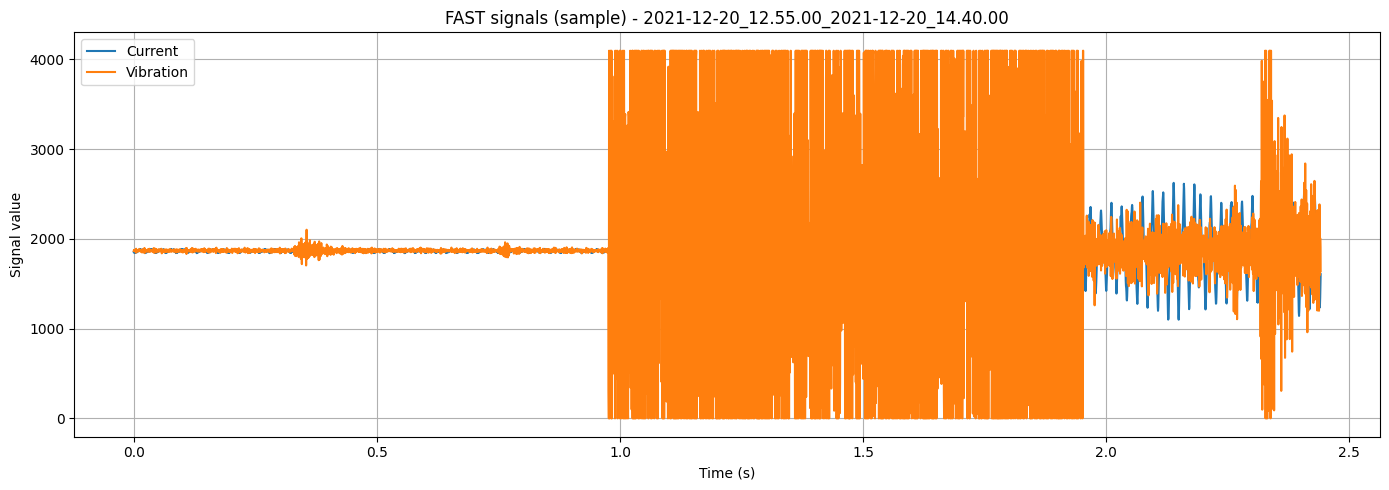

Saved: D:\PROJECT\SMART-PDM-Dataset-Layer1\audit_v3\plots\2021-12-20_12.55.00_2021-12-20_14.40.00_FAST_sample.png

Example fault: 2022-04-04_10.17.00_2022-04-04_11.55.00


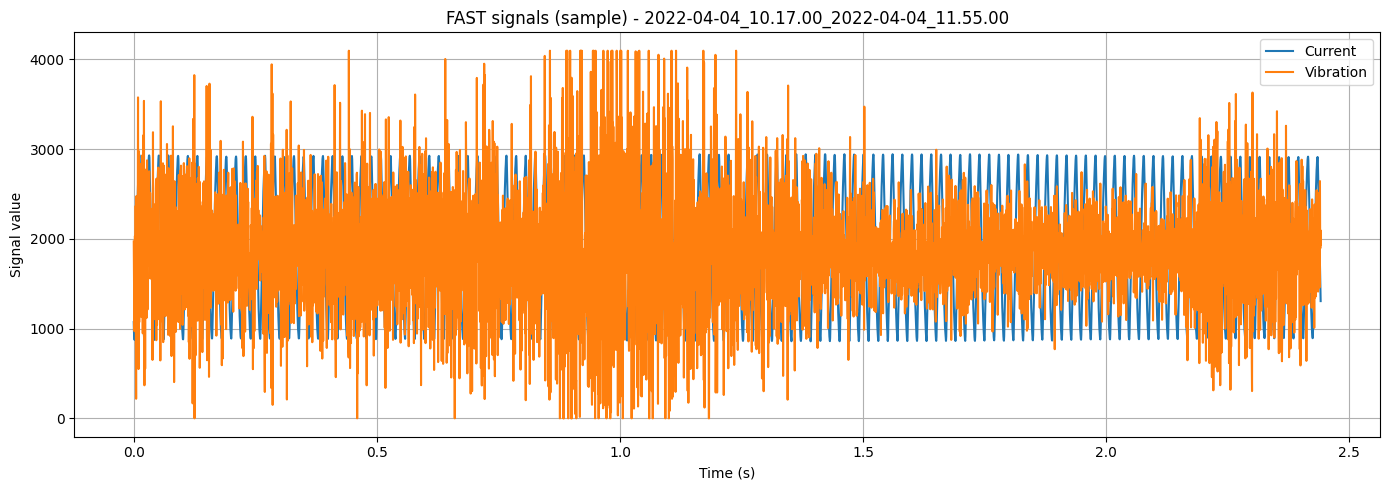

Saved: D:\PROJECT\SMART-PDM-Dataset-Layer1\audit_v3\plots\2022-04-04_10.17.00_2022-04-04_11.55.00_FAST_sample.png


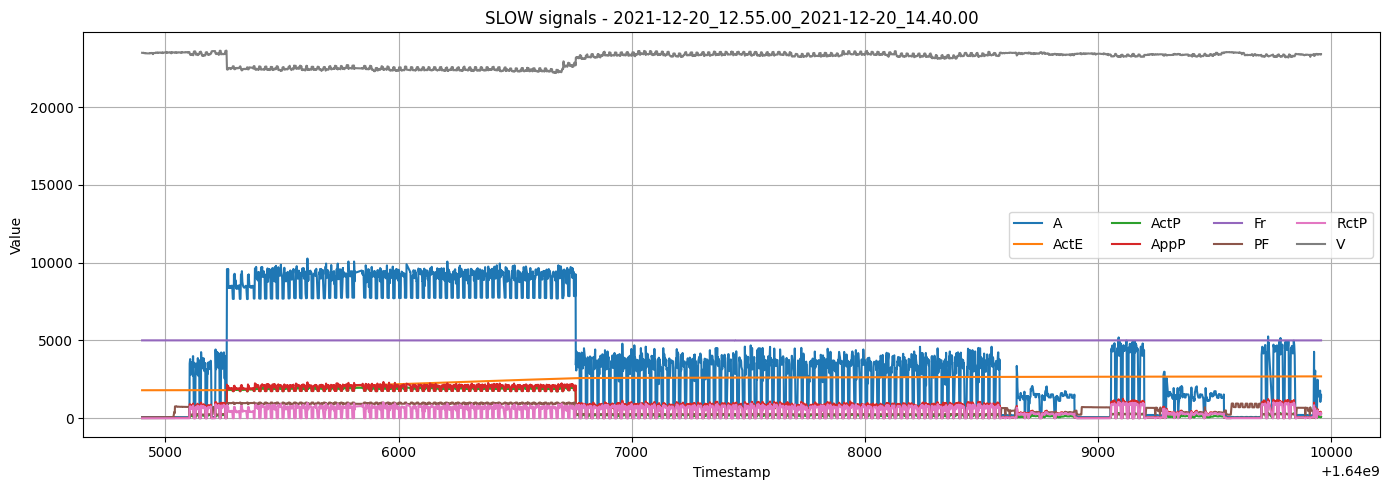

Saved: D:\PROJECT\SMART-PDM-Dataset-Layer1\audit_v3\plots\2021-12-20_12.55.00_2021-12-20_14.40.00_SLOW.png
FINAL RAW SIGNAL AUDIT STATUS

STATUS: REVIEW_REQUIRED

Critical issues:
 - 1 FAST file(s) are empty.

IMPORTANT: Outliers and duplicate values are descriptive only and were NOT used to delete data.
Reports saved to: D:\PROJECT\SMART-PDM-Dataset-Layer1\audit_v3\reports


SMART-PDM — LAYER 1 RAW SIGNAL AUDIT V3 (Streaming)

Final status: REVIEW_REQUIRED

--- DATASET ---
Total cycles: 96
Expected files: 192
Audited files: 192

--- FILE HEALTH ---
Read failures: 0
Empty FAST files: 1
Empty SLOW files: 0

--- STRUCTURE ---
Files with missing expected columns: 0

--- SAMPLING ---
FAST fs median: 2049.1803 Hz  (expected ≈ 2049.0)
SLOW fs median: 1.0000 Hz  (expected ≈ 1.0)
Files requiring sampling review: 0

--- SIGNAL QUALITY ---
Signal instances with NaN/Inf: 0
Constant/near-constant instances: 28
Files with skipped duplicate-check: 83

--- EXPECTED SIGNALS ---
FAST: ['Current', 'Vibr

In [2]:
# ============================================================
# CELL 17 — SIGNAL-LEVEL AUDIT (Streaming روی نمونه‌ها)
# ============================================================

def robust_signal_stats(series, iqr_multiplier=IQR_MULTIPLIER):
    """
    آماره‌های مقاوم روی یک نمونه‌ی محدود (نه streaming).
    برای استفاده در CELL 17 که روی sample_data کار می‌کند.
    """
    x = pd.to_numeric(series, errors="coerce").dropna()

    result = {
        "n": int(len(x)),
        "n_nan_or_invalid": int(len(series) - len(x)),
        "mean": np.nan, "std": np.nan, "min": np.nan,
        "q01": np.nan, "q25": np.nan, "median": np.nan,
        "q75": np.nan, "q99": np.nan, "max": np.nan,
        "iqr": np.nan,
        "outlier_count_iqr3": 0,
        "outlier_ratio_iqr3": np.nan,
        "is_constant": False, "is_near_constant": False,
    }
    if len(x) == 0:
        return result

    q01, q25, q50, q75, q99 = np.percentile(x, [1, 25, 50, 75, 99])
    iqr = q75 - q25
    lower = q25 - iqr_multiplier * iqr
    upper = q75 + iqr_multiplier * iqr
    outliers = (x < lower) | (x > upper)
    std = x.std()

    result.update({
        "mean": float(x.mean()),
        "std": float(std),
        "min": float(x.min()),
        "q01": float(q01), "q25": float(q25), "median": float(q50),
        "q75": float(q75), "q99": float(q99), "max": float(x.max()),
        "iqr": float(iqr),
        "outlier_count_iqr3": int(outliers.sum()),
        "outlier_ratio_iqr3": float(outliers.mean()),
        "is_constant": bool(np.allclose(x.to_numpy(), x.iloc[0])),
        "is_near_constant": bool(std <= NEAR_CONSTANT_STD_EPS),
    })
    return result


signal_results = []

for idx, row in audit_manifest.iterrows():

    cycle_id = row["cycle_id_std"]
    split    = row["split_std"]
    label    = row["label_std"]

    for modality, signals in [
        ("FAST", FAST_SIGNAL_COLUMNS),
        ("SLOW", SLOW_SIGNAL_COLUMNS),
    ]:
        key = (cycle_id, modality)
        if key not in sample_data:
            continue

        df = sample_data[key]
        for signal in signals:
            if signal not in df.columns:
                continue

            stats = robust_signal_stats(df[signal], iqr_multiplier=IQR_MULTIPLIER)
            stats.update({
                "cycle_id": cycle_id, "split": split, "label": label,
                "modality": modality, "signal": signal,
            })
            signal_results.append(stats)


signal_audit = pd.DataFrame(signal_results)
print("Signal audit rows (sample-based):", len(signal_audit))
display(signal_audit.head())


# ============================================================
# CELL 18 — CONSTANT / NEAR-CONSTANT
# ============================================================

constant_signals = signal_audit[
    signal_audit["is_constant"] | signal_audit["is_near_constant"]
].copy() if len(signal_audit) > 0 else pd.DataFrame()

print("Constant / near-constant signal instances:", len(constant_signals))
if len(constant_signals) > 0:
    display(
        constant_signals[
            ["cycle_id", "split", "label", "modality", "signal",
             "n", "mean", "std", "is_constant", "is_near_constant"]
        ].head(100)
    )


# ============================================================
# CELL 19 — OUTLIER SUMMARY
# ============================================================

if len(signal_audit) > 0:
    outlier_summary = (
        signal_audit
        .groupby(["modality", "signal"])["outlier_ratio_iqr3"]
        .agg(["count", "median", "mean", "min", "max"])
        .reset_index()
    )
    display(outlier_summary)
else:
    outlier_summary = pd.DataFrame()


# ============================================================
# CELL 20 — NaN / INF AUDIT (نمونه‌ها)
# ============================================================

nan_inf_results = []
for (cycle_id, modality), df in sample_data.items():
    signals = FAST_SIGNAL_COLUMNS if modality == "FAST" else SLOW_SIGNAL_COLUMNS
    for signal in signals:
        if signal not in df.columns:
            continue
        x = pd.to_numeric(df[signal], errors="coerce")
        n_nan = int(x.isna().sum())
        n_inf = int(np.isinf(x.to_numpy(dtype=float)).sum())
        nan_inf_results.append({
            "cycle_id": cycle_id,
            "modality": modality,
            "signal": signal,
            "n_rows": len(df),
            "n_nan": n_nan,
            "n_inf": n_inf,
            "nan_ratio": n_nan / len(df) if len(df) > 0 else np.nan,
            "inf_ratio": n_inf / len(df) if len(df) > 0 else np.nan,
        })

nan_inf_audit = pd.DataFrame(nan_inf_results)

if len(nan_inf_audit) > 0:
    display(nan_inf_audit.head())
    print("\nSignals with NaN or Inf:")
    display(
        nan_inf_audit[
            (nan_inf_audit["n_nan"] > 0) | (nan_inf_audit["n_inf"] > 0)
        ]
    )


# ============================================================
# CELL 21 — FAST STRUCTURE CHECK
# ============================================================

fast_structure = []
for key, df in sample_data.items():
    cycle_id, modality = key
    if modality != "FAST":
        continue
    fast_structure.append({
        "cycle_id": cycle_id,
        "n_rows": len(df),
        "has_time": FAST_TIME_COLUMN in df.columns,
        "has_current": "Current" in df.columns,
        "has_vibration": "Vibration" in df.columns,
    })

fast_structure = pd.DataFrame(fast_structure)
if len(fast_structure) > 0:
    display(fast_structure)
    print("\nFAST structure problems:")
    display(
        fast_structure[
            ~(fast_structure["has_time"] & fast_structure["has_current"] & fast_structure["has_vibration"])
        ]
    )


# ============================================================
# CELL 22 — SLOW STRUCTURE CHECK
# ============================================================

slow_structure = []
for key, df in sample_data.items():
    cycle_id, modality = key
    if modality != "SLOW":
        continue
    row = {
        "cycle_id": cycle_id,
        "n_rows": len(df),
        "has_time": SLOW_TIME_COLUMN in df.columns,
    }
    for signal in SLOW_SIGNAL_COLUMNS:
        row[f"has_{signal}"] = signal in df.columns
    slow_structure.append(row)

slow_structure = pd.DataFrame(slow_structure)
if len(slow_structure) > 0:
    display(slow_structure)
    required_slow_cols = ["has_time"] + [f"has_{s}" for s in SLOW_SIGNAL_COLUMNS]
    slow_structure["all_required"] = slow_structure[required_slow_cols].all(axis=1)
    print("\nSLOW structure problems:")
    display(slow_structure[~slow_structure["all_required"]])


# ============================================================
# CELL 23 — PLOT FAST (نمونه)
# ============================================================

def plot_fast_cycle(cycle_id, max_points=30000):
    key = (cycle_id, "FAST")
    if key not in sample_data:
        print("FAST sample not available:", cycle_id)
        return

    df = sample_data[key]
    if FAST_TIME_COLUMN not in df.columns:
        print("Timestamp not found.")
        return

    t = pd.to_numeric(df[FAST_TIME_COLUMN], errors="coerce") / 1e6
    fig, ax = plt.subplots(figsize=(14, 5))
    for signal in FAST_SIGNAL_COLUMNS:
        if signal not in df.columns:
            continue
        x = pd.to_numeric(df[signal], errors="coerce")
        n = min(len(df), max_points)
        ax.plot(t.iloc[:n], x.iloc[:n], label=signal)

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Signal value")
    ax.set_title(f"FAST signals (sample) - {cycle_id}")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()

    out = PLOT_DIR / f"{cycle_id}_FAST_sample.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


normal_cycles = audit_manifest[
    audit_manifest["label_std"] == "Normal"
]["cycle_id_std"].tolist()
fault_cycles = audit_manifest[
    audit_manifest["label_std"] != "Normal"
]["cycle_id_std"].tolist()

if normal_cycles:
    print("\nExample normal:", normal_cycles[0])
    plot_fast_cycle(normal_cycles[0])
if fault_cycles:
    print("\nExample fault:", fault_cycles[0])
    plot_fast_cycle(fault_cycles[0])


# ============================================================
# CELL 24 — PLOT SLOW (نمونه)
# ============================================================

def plot_slow_cycle(cycle_id):
    key = (cycle_id, "SLOW")
    if key not in sample_data:
        print("SLOW sample not available:", cycle_id)
        return
    df = sample_data[key]
    if SLOW_TIME_COLUMN not in df.columns:
        print("SLOW timestamp not found.")
        return

    t = pd.to_numeric(df[SLOW_TIME_COLUMN], errors="coerce")
    fig, ax = plt.subplots(figsize=(14, 5))
    for signal in SLOW_SIGNAL_COLUMNS:
        if signal not in df.columns:
            continue
        x = pd.to_numeric(df[signal], errors="coerce")
        ax.plot(t, x, label=signal)

    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Value")
    ax.set_title(f"SLOW signals - {cycle_id}")
    ax.legend(ncol=4)
    ax.grid(True)
    plt.tight_layout()

    out = PLOT_DIR / f"{cycle_id}_SLOW.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


if normal_cycles:
    plot_slow_cycle(normal_cycles[0])


# ============================================================
# CELL 25 — FINAL AUDIT STATUS
# ============================================================

audit_status = {
    "total_cycles": int(len(audit_manifest)),
    "total_files_expected": int(len(audit_manifest) * 2),
    "total_files_audited": int(len(file_audit)),
    "read_success_files": int(file_audit["read_success"].sum()),
    "empty_files": int(file_audit["empty_file"].sum()),
    "files_missing_expected_columns": int(
        (file_audit["missing_expected_signals"].astype(str).str.len() > 0).sum()
    ),
    "fast_files": int((file_audit["modality"] == "FAST").sum()),
    "slow_files": int((file_audit["modality"] == "SLOW").sum()),
    "fast_empty_files": int(
        ((file_audit["modality"] == "FAST") & (file_audit["empty_file"] == True)).sum()
    ),
    "slow_empty_files": int(
        ((file_audit["modality"] == "SLOW") & (file_audit["empty_file"] == True)).sum()
    ),
    "sampling_check_files": int((sampling_detail["sampling_status"] == "CHECK").sum()),
    "signals_with_nan_or_inf": int(
        ((nan_inf_audit["n_nan"] > 0) | (nan_inf_audit["n_inf"] > 0)).sum()
    ) if len(nan_inf_audit) > 0 else 0,
    "duplicate_check_skipped_files": int((file_audit["duplicate_check_skipped"] == True).sum()),
}

audit_status


# ============================================================
# CELL 26 — AUTOMATIC DECISION
# ============================================================

critical_issues = []

read_failures = file_audit[~file_audit["read_success"]]
if len(read_failures) > 0:
    critical_issues.append(f"{len(read_failures)} file(s) could not be read.")

if audit_status["fast_empty_files"] > 0:
    critical_issues.append(f"{audit_status['fast_empty_files']} FAST file(s) are empty.")

if audit_status["files_missing_expected_columns"] > 0:
    critical_issues.append(
        f"{audit_status['files_missing_expected_columns']} file(s) have missing expected columns."
    )

if audit_status["sampling_check_files"] > 0:
    critical_issues.append(
        f"{audit_status['sampling_check_files']} file(s) have suspicious sampling rate."
    )

if audit_status["signals_with_nan_or_inf"] > 0:
    critical_issues.append(
        f"{audit_status['signals_with_nan_or_inf']} signal instances contain NaN/Inf."
    )

FINAL_STATUS = "PASS" if len(critical_issues) == 0 else "REVIEW_REQUIRED"

print("=" * 70)
print("FINAL RAW SIGNAL AUDIT STATUS")
print("=" * 70)
print("\nSTATUS:", FINAL_STATUS)

if critical_issues:
    print("\nCritical issues:")
    for issue in critical_issues:
        print(" -", issue)
else:
    print("\nNo critical structural problems detected.")

print("\nIMPORTANT: Outliers and duplicate values are descriptive only and were NOT used to delete data.")


# ============================================================
# CELL 27 — SAVE REPORTS
# ============================================================

file_audit.to_csv(REPORT_DIR / "raw_file_audit_v3.csv", index=False, encoding="utf-8-sig")
signal_audit.to_csv(REPORT_DIR / "signal_audit_v3.csv", index=False, encoding="utf-8-sig")
if len(nan_inf_audit) > 0:
    nan_inf_audit.to_csv(REPORT_DIR / "nan_inf_audit_v3.csv", index=False, encoding="utf-8-sig")
sampling_detail.to_csv(REPORT_DIR / "sampling_audit_v3.csv", index=False, encoding="utf-8-sig")
if len(constant_signals) > 0:
    constant_signals.to_csv(REPORT_DIR / "constant_signal_audit_v3.csv", index=False, encoding="utf-8-sig")

with open(REPORT_DIR / "audit_status_v3.json", "w", encoding="utf-8") as f:
    json.dump({
        "final_status": FINAL_STATUS,
        "audit_status": audit_status,
        "critical_issues": critical_issues,
        "signal_definitions": {
            "FAST_time": FAST_TIME_COLUMN,
            "FAST_signals": FAST_SIGNAL_COLUMNS,
            "SLOW_time": SLOW_TIME_COLUMN,
            "SLOW_signals": SLOW_SIGNAL_COLUMNS,
        },
        "expected_sampling": {
            "FAST_Hz": EXPECTED_FAST_FS,
            "SLOW_Hz": EXPECTED_SLOW_FS,
        },
        "chunked_policy": {
            "CHUNK_SIZE": CHUNK_SIZE,
            "MAX_SAMPLE_ROWS": MAX_SAMPLE_ROWS,
            "MAX_TS_HASH_SET": MAX_TS_HASH_SET,
        },
        "outlier_policy": "Descriptive only; no samples removed.",
        "duplicate_policy": "Reported only; no rows removed.",
    }, f, indent=2, ensure_ascii=False)

print("Reports saved to:", REPORT_DIR)


# ============================================================
# CELL 28 — HUMAN-READABLE SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("SMART-PDM — LAYER 1 RAW SIGNAL AUDIT V3 (Streaming)")
print("=" * 80)

print(f"\nFinal status: {FINAL_STATUS}")

print("\n--- DATASET ---")
print(f"Total cycles: {audit_status['total_cycles']}")
print(f"Expected files: {audit_status['total_files_expected']}")
print(f"Audited files: {audit_status['total_files_audited']}")

print("\n--- FILE HEALTH ---")
print(f"Read failures: {audit_status['total_files_audited'] - audit_status['read_success_files']}")
print(f"Empty FAST files: {audit_status['fast_empty_files']}")
print(f"Empty SLOW files: {audit_status['slow_empty_files']}")

print("\n--- STRUCTURE ---")
print(f"Files with missing expected columns: {audit_status['files_missing_expected_columns']}")

print("\n--- SAMPLING ---")
fast_fs = file_audit[(file_audit["modality"] == "FAST") & file_audit["read_success"]]["estimated_fs_hz"].dropna()
slow_fs = file_audit[(file_audit["modality"] == "SLOW") & file_audit["read_success"]]["estimated_fs_hz"].dropna()
if len(fast_fs):
    print(f"FAST fs median: {fast_fs.median():.4f} Hz  (expected ≈ {EXPECTED_FAST_FS})")
if len(slow_fs):
    print(f"SLOW fs median: {slow_fs.median():.4f} Hz  (expected ≈ {EXPECTED_SLOW_FS})")
print(f"Files requiring sampling review: {audit_status['sampling_check_files']}")

print("\n--- SIGNAL QUALITY ---")
print(f"Signal instances with NaN/Inf: {audit_status['signals_with_nan_or_inf']}")
print(f"Constant/near-constant instances: {len(constant_signals)}")
print(f"Files with skipped duplicate-check: {audit_status['duplicate_check_skipped_files']}")

print("\n--- EXPECTED SIGNALS ---")
print("FAST:", FAST_SIGNAL_COLUMNS)
print("FAST timestamp:", FAST_TIME_COLUMN, "(microseconds)")
print("SLOW:", SLOW_SIGNAL_COLUMNS)
print("SLOW timestamp:", SLOW_TIME_COLUMN, "(seconds)")

print("\n--- DECISION ---")
if FINAL_STATUS == "PASS":
    print("AUDIT PASSED.")
    print("Next step can be Layer 1 windowing.")
else:
    print("AUDIT REQUIRES REVIEW.")
    print("Do NOT start model training yet.")
    print("\nIssues:")
    for issue in critical_issues:
        print(" -", issue)

print("\n" + "=" * 80)